# Credit Risk Model Pipeline — Modular Notebook

**Lending Club Dataset (~80,000 rows)**  
**Models:** Logistic Regression vs XGBoost  
**Objective:** Maximize Expected Value via optimal threshold tuning

---
วิธีใช้: **กด `Shift+Enter` ทีละ cell** เพื่อรันทีละ Step ดู output แต่ละขั้นตอน

> ⚠️ ต้องรัน **ตามลำดับ** เพราะแต่ละ Step ใช้ตัวแปรจาก Step ก่อนหน้า

## Cell 0 — Imports & Configuration
ติดตั้ง dependencies และกำหนด global constants ทั้งหมด

In [1]:
import logging
import warnings
import sys
from pathlib import Path
from typing import Tuple, Dict, Any

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix,
    classification_report,
)
from sklearn.calibration import calibration_curve

import xgboost as xgb
import shap

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
%matplotlib inline

warnings.filterwarnings('ignore', category=FutureWarning)

# ──────────────────────────────────────────────
# POSITIVE CLASS — single source of truth
# ──────────────────────────────────────────────
# loan_status == "Charged Off"  →  1  (POSITIVE = borrower defaulted)
# loan_status == "Fully Paid"   →  0  (NEGATIVE = borrower repaid)
#
# TP (True Positive)  : Predict default, actual default   → avoided a bad loan
# TN (True Negative)  : Predict repay,   actual repay     → earned profit
# FP (False Positive) : Predict default, actual repay     → missed good loan (opportunity cost)
# FN (False Negative) : Predict repay,   actual default   → funded bad loan (loss)
# ──────────────────────────────────────────────
POSITIVE_CLASS_LABEL = "Charged Off"
POSITIVE_CLASS = 1

NUMERIC_FEATURES = [
    "loan_amnt", "int_rate", "installment", "annual_inc", "dti",
    "fico_range_low", "fico_range_high", "open_acc", "pub_rec",
    "revol_util", "mort_acc",
    "emp_length_missing",  # missing indicator — คนไม่กรอก = เสี่ยงสูง
]
CATEGORICAL_FEATURES = ["purpose", "home_ownership"]
ORDINAL_FEATURES = ["term", "emp_length"]

TERM_MAP = {"36 months": 0, "60 months": 1}
EMP_LENGTH_ORDER = [
    "< 1 year", "1 year", "2 years", "3 years", "4 years",
    "5 years", "6 years", "7 years", "8 years", "9 years", "10+ years",
]

RANDOM_STATE = 42

# ──────────────────────────────────────────────
# Logging — output จะแสดงใน cell output
# ──────────────────────────────────────────────
log = logging.getLogger("credit_risk")
log.setLevel(logging.INFO)
log.handlers.clear()
_fmt = logging.Formatter(
    fmt="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%H:%M:%S",
)
_ch = logging.StreamHandler(sys.stdout)
_ch.setFormatter(_fmt)
log.addHandler(_ch)

log.info("✅ All imports loaded. Ready to go.")

20:56:27 | INFO     | ✅ All imports loaded. Ready to go.


---
## Step 1 — Load + Feature Selection + Missing Data Strategy + Business Params
โหลด CSV, กรองเฉพาะ Fully Paid / Charged Off, encode ordinal features,  
**Imputation strategy** (จากการวิเคราะห์ missing pattern):  
- `emp_length` (5.84%) — หายแบบ MAR → สร้าง `emp_length_missing` flag + เติม median  
- `mort_acc` (3.50%) — เติม median  
- `dti` / `revol_util` (< 0.1%) — ลบทิ้ง (negligible)

In [2]:
import os
import pandas as pd
from pathlib import Path

# 👉 ระบุ Path ให้ตรงกับไฟล์
# วางไฟล์ไว้ที่ data/lending_club_80k.csv (รันได้ทั้งจาก root ของ repo และจากโฟลเดอร์ notebooks/)
DATA_PATH = next(p for p in [Path('data/lending_club_80k.csv'), Path('../data/lending_club_80k.csv')] if p.exists())

log.info('Loading dataset from %s', DATA_PATH)

# Read CSV file และลบแถวที่ซ้ำกัน พร้อมเรียง Index ใหม่ทันที
df_raw = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
log.info('Raw shape: %s', df_raw.shape)

# Keep only Fully Paid / Charged Off
df = df_raw[df_raw['loan_status'].isin(['Fully Paid', POSITIVE_CLASS_LABEL])].copy()
log.info('After filtering loan_status: %s', df.shape)

# Encode target
df['target'] = (df['loan_status'] == POSITIVE_CLASS_LABEL).astype(int)
print('\n📊 Target distribution:')
print(df['target'].value_counts())
print(f'Default rate: {df["target"].mean():.2%}')

# Select features
# Select features
all_features = NUMERIC_FEATURES + CATEGORICAL_FEATURES + ORDINAL_FEATURES
# ไม่ต้องบวก loan_amnt กับ installment เพิ่มแล้ว เพราะมันอยู่ใน all_features แล้ว
keep_cols = all_features + ['target', 'loan_status'] 

df = df[[c for c in keep_cols if c in df.columns]].copy()
# กันเหนียว: ลบคอลัมน์ที่ชื่อซ้ำกันทิ้งไปให้หมด
df = df.loc[:, ~df.columns.duplicated()].copy()
# Ordinal encoding
df['term'] = df['term'].str.strip().map(TERM_MAP)
df['emp_length'] = df['emp_length'].str.strip()
emp_map = {v: i for i, v in enumerate(EMP_LENGTH_ORDER)}
df['emp_length'] = df['emp_length'].map(emp_map)

# ── Missing Data Strategy ──
# 1) สร้าง missing indicator BEFORE เติมค่า
df['emp_length_missing'] = df['emp_length'].isnull().astype(int)
log.info('emp_length_missing flag created — %d rows flagged (%.2f%%)',
         df['emp_length_missing'].sum(), df['emp_length_missing'].mean() * 100)

# 2) Impute emp_length & mort_acc ด้วย median
emp_median = df['emp_length'].median()
mort_median = df['mort_acc'].median()
df['emp_length'] = df['emp_length'].fillna(emp_median)
df['mort_acc']   = df['mort_acc'].fillna(mort_median)
log.info('Imputed emp_length with median=%.1f, mort_acc with median=%.1f', emp_median, mort_median)

# 3) dti & revol_util — แค่ 62 แถว → drop ได้เลย
before = len(df)
df.dropna(subset=['dti', 'revol_util', 'target'], inplace=True)
log.info('Dropped %d rows with NaN in dti/revol_util → remaining %d', before - len(df), len(df))

# 👉 ล้างไพ่ Index ให้ df หลังจาก Drop NaN (เพื่อป้องกัน Index พังตอนคำนวณ)
df = df.reset_index(drop=True)

# ── Business Parameters (from ACTUAL payment data) ──

# ดึง total_pymnt มาแปะไว้ใน df ก่อน (โดยใช้ Index ที่ตรงกันแบบเป๊ะๆ)
if 'total_pymnt' in df_raw.columns:
    # df_raw.loc[df_raw.index.isin(...)] ช่วยดึงข้อมูลมาให้ตรงกับแถวที่เหลือรอด
    # แต่เนื่องจากเราอาจจะงง Index เราใช้การดึงแบบปลอดภัยที่สุด
    df_raw_filtered = df_raw.loc[df_raw['loan_status'].isin(['Fully Paid', POSITIVE_CLASS_LABEL])].dropna(subset=['dti', 'revol_util']).reset_index(drop=True)
    df['total_pymnt'] = df_raw_filtered['total_pymnt']
else:
    df['total_pymnt'] = df['installment'] * df['term'].map({0:36, 1:60})

# สร้าง Mask โดยอิงจาก df ล้วนๆ
mask_fp = df['target'] == 0
mask_co = df['target'] == 1

# PROFIT_TN: ดอกเบี้ยที่ได้จริงจากคนที่จ่ายครบ
profit_tn = float((df.loc[mask_fp, 'total_pymnt'] - df.loc[mask_fp, 'loan_amnt']).median())

# LOSS_FN: ขาดทุนสุทธิจากคนเบี้ยว = เงินต้น - ส่วนที่เก็บคืนได้
loss_fn = float((df.loc[mask_co, 'loan_amnt'] - df.loc[mask_co, 'total_pymnt']).median())

# จุดอ้างอิง = ไม่ปล่อยกู้เลย (ได้ 0) ทุก outcome คิดเทียบกับจุดนี้ครั้งเดียว
# COST_FP: ปฏิเสธคนดี → ไม่ได้ดอกเบี้ย แต่ก็ไม่เสียเงิน = 0
#   (กำไรที่พลาดไปถูกสะท้อนแล้วจากการที่ไม่ได้ PROFIT_TN ถ้านับซ้ำอีกจะเป็น double counting)
cost_fp = 0.0

# REWARD_TP: ปฏิเสธคนเบี้ยว → ไม่ได้ไม่เสีย = 0
#   (เวอร์ชันแรกให้ +เงินต้นเต็มก้อน ซึ่งนับซ้ำกับ LOSS_FN ทำให้ 'Reject All' ดูกำไรเกือบเท่าโมเดล)
reward_tp = 0.0

business_params = {
    'PROFIT_TN':  profit_tn,   
    'LOSS_FN':    loss_fn,     
    'COST_FP':    cost_fp,     
    'REWARD_TP':  reward_tp,   
}

df.drop(columns=['loan_status', 'total_pymnt'], inplace=True, errors='ignore')

print('\n💰 Business Parameters (from actual payment data):')
for k, v in business_params.items():
    print(f'  {k:12s} = ${v:>10,.2f}')
print(f'\n  ⚠️ ค่าทั้ง 4 ต่างกัน — สะท้อนความจริงที่ว่า:')
print(f'    ขาดทุนจากคนเบี้ยว (${loss_fn:,.0f}) >> กำไรจากคนดี (${profit_tn:,.0f})')
print('    ปฏิเสธ = 0 เสมอ ดังนั้น Reject All ต้องได้ EV = 0 พอดี')

print(f'\n📐 Final dataset shape: {df.shape}')
df.head()

20:56:27 | INFO     | Loading dataset from ../data/lending_club_80k.csv


20:56:28 | INFO     | Raw shape: (80000, 151)


20:56:28 | INFO     | After filtering loan_status: (80000, 151)



📊 Target distribution:
target
0    64150
1    15850
Name: count, dtype: int64
Default rate: 19.81%
20:56:28 | INFO     | emp_length_missing flag created — 4669 rows flagged (5.84%)


20:56:28 | INFO     | Imputed emp_length with median=6.0, mort_acc with median=1.0


20:56:28 | INFO     | Dropped 62 rows with NaN in dti/revol_util → remaining 79938



💰 Business Parameters (from actual payment data):
  PROFIT_TN    = $  1,518.50
  LOSS_FN      = $  5,711.90
  COST_FP      = $      0.00
  REWARD_TP    = $      0.00

  ⚠️ ค่าทั้ง 4 ต่างกัน — สะท้อนความจริงที่ว่า:
    ขาดทุนจากคนเบี้ยว ($5,712) >> กำไรจากคนดี ($1,518)
    ปฏิเสธ = 0 เสมอ ดังนั้น Reject All ต้องได้ EV = 0 พอดี

📐 Final dataset shape: (79938, 17)


,loan_amnt,int_rate,installment,annual_inc,dti,fico_range_low,fico_range_high,open_acc,pub_rec,revol_util,mort_acc,purpose,home_ownership,term,emp_length,target,emp_length_missing
0,8000,7.69,249.55,80000.0,8.73,680,684,11,0,39.9,6.0,debt_consolidation,MORTGAGE,0,1.0,0,0
1,12000,15.05,416.28,36000.0,17.86,660,664,7,0,58.3,0.0,debt_consolidation,OWN,0,0.0,0,0
2,8000,12.99,269.52,26000.0,27.98,680,684,11,1,56.9,0.0,debt_consolidation,RENT,0,2.0,0,0
3,5000,11.49,164.86,28000.0,12.69,685,689,5,0,68.8,0.0,other,OWN,0,6.0,0,1
4,30800,11.99,1022.86,150000.0,16.28,700,704,15,0,53.9,2.0,credit_card,MORTGAGE,0,10.0,0,0


---
## Step 2 — Train / Val / Test Split (60 / 20 / 20)
Stratified split → reset_index ทุกตัว

In [3]:
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES + ORDINAL_FEATURES]
y = df['target']

# 60% train vs 40% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
# 50% of 40% = 20% val, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

# Reset indices
for d in [X_train, X_val, X_test, y_train, y_val, y_test]:
    d.reset_index(drop=True, inplace=True)

log.info('Train: %d | Val: %d | Test: %d', len(X_train), len(X_val), len(X_test))

print(f'\n📊 Positive-class rate:')
print(f'  Train: {y_train.mean():.4f}')
print(f'  Val:   {y_val.mean():.4f}')
print(f'  Test:  {y_test.mean():.4f}')
print(f'\n✅ Indices reset — X_train.index[0]={X_train.index[0]}, X_val.index[0]={X_val.index[0]}, X_test.index[0]={X_test.index[0]}')

20:56:28 | INFO     | Train: 47962 | Val: 15988 | Test: 15988



📊 Positive-class rate:
  Train: 0.1982
  Val:   0.1981
  Test:  0.1981

✅ Indices reset — X_train.index[0]=0, X_val.index[0]=0, X_test.index[0]=0


---
## Step 3 — Dual Preprocessor (LR vs XGBoost)
- **LR:** StandardScaler + OneHotEncoder(`drop_first=True`)  
- **XGB:** StandardScaler + OneHotEncoder(`drop_first=False`)  
- `fit` เฉพาะ Train → `transform` Val/Test

In [4]:
def _build_preprocessor(drop_first: bool) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), NUMERIC_FEATURES),
            ('cat', OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False,
                drop='first' if drop_first else None,
            ), CATEGORICAL_FEATURES),
            ('ord', 'passthrough', ORDINAL_FEATURES),
        ],
        remainder='drop',
    )

preprocessed = {}
for name, drop_first in [('lr', True), ('xgb', False)]:
    pre = _build_preprocessor(drop_first=drop_first)
    Xt_train = pre.fit_transform(X_train)   # fit on Train ONLY
    Xt_val   = pre.transform(X_val)          # transform only
    Xt_test  = pre.transform(X_test)         # transform only
    
    feature_names = pre.get_feature_names_out()
    preprocessed[name] = {
        'train': Xt_train, 'val': Xt_val, 'test': Xt_test,
        'preprocessor': pre, 'feature_names': feature_names,
    }
    log.info('%s preprocessor — output dims: %s (features: %d)',
             name.upper(), Xt_train.shape, len(feature_names))

print(f'\n✅ LR features:  {preprocessed["lr"]["train"].shape[1]}')
print(f'✅ XGB features: {preprocessed["xgb"]["train"].shape[1]}')
print(f'\nLR feature names: {list(preprocessed["lr"]["feature_names"][:5])} ... ({len(preprocessed["lr"]["feature_names"])} total)')
print(f'XGB feature names: {list(preprocessed["xgb"]["feature_names"][:5])} ... ({len(preprocessed["xgb"]["feature_names"])} total)')

20:56:28 | INFO     | LR preprocessor — output dims: (47962, 32) (features: 32)


20:56:28 | INFO     | XGB preprocessor — output dims: (47962, 34) (features: 34)



✅ LR features:  32
✅ XGB features: 34

LR feature names: ['num__loan_amnt', 'num__int_rate', 'num__installment', 'num__annual_inc', 'num__dti'] ... (32 total)
XGB feature names: ['num__loan_amnt', 'num__int_rate', 'num__installment', 'num__annual_inc', 'num__dti'] ... (34 total)


---
## Step 4 — Train Models (LR + XGBoost)

In [5]:
models = {}

# ── Logistic Regression ──
log.info('Training Logistic Regression...')
lr = LogisticRegression(
    solver='saga', penalty='l2', C=1.0,
    max_iter=2000, random_state=RANDOM_STATE, n_jobs=-1,
)
lr.fit(preprocessed['lr']['train'], y_train)
models['lr'] = lr
log.info('LR converged in %d iterations', lr.n_iter_[0])

# ── XGBoost ──
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
log.info('Training XGBoost (scale_pos_weight=%.2f)...', pos_weight)
xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=pos_weight, eval_metric='auc',
    use_label_encoder=False, random_state=RANDOM_STATE, n_jobs=-1,
)
xgb_model.fit(preprocessed['xgb']['train'], y_train, verbose=False)
models['xgb'] = xgb_model

print(f'\n✅ LR — converged in {lr.n_iter_[0]} iterations')
print(f'✅ XGB — {xgb_model.n_estimators} estimators, max_depth={xgb_model.max_depth}')

20:56:28 | INFO     | Training Logistic Regression...


20:57:03 | INFO     | LR converged in 2000 iterations


20:57:03 | INFO     | Training XGBoost (scale_pos_weight=4.05)...



✅ LR — converged in 2000 iterations
✅ XGB — 300 estimators, max_depth=5


---
## Step 5 — Predict Probability + Expected Value Function
กำหนด utility functions ที่จะใช้ใน Step ถัดไป

In [6]:
def predict_proba_positive(model, X):
    """Return P(Charged Off)"""
    return model.predict_proba(X)[:, POSITIVE_CLASS]


def compute_expected_value(y_true, y_pred, bp):
    """
    EV = (TN × PROFIT_TN) − (FN × LOSS_FN) − (FP × COST_FP) + (TP × REWARD_TP)
    เทียบกับการไม่ปล่อยกู้ (= 0): COST_FP = REWARD_TP = 0 จึงเหลือ TN × PROFIT_TN − FN × LOSS_FN
    
    sklearn confusion_matrix order: [[TN, FP], [FN, TP]]
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return (tn * bp['PROFIT_TN']) - (fn * bp['LOSS_FN']) - (fp * bp['COST_FP']) + (tp * bp['REWARD_TP'])


# Quick sanity check — LR proba on val
lr_proba_val = predict_proba_positive(models['lr'], preprocessed['lr']['val'])
print(f'LR P(default) on Val — min: {lr_proba_val.min():.4f}, mean: {lr_proba_val.mean():.4f}, max: {lr_proba_val.max():.4f}')

xgb_proba_val = predict_proba_positive(models['xgb'], preprocessed['xgb']['val'])
print(f'XGB P(default) on Val — min: {xgb_proba_val.min():.4f}, mean: {xgb_proba_val.mean():.4f}, max: {xgb_proba_val.max():.4f}')

print('\n✅ EV function defined and proba sanity-checked.')

LR P(default) on Val — min: 0.0160, mean: 0.2009, max: 0.9964
XGB P(default) on Val — min: 0.0183, mean: 0.4446, max: 0.9194

✅ EV function defined and proba sanity-checked.


---
## Step 6 — Threshold Tuning Loop (Val set only)
Sweep 200 thresholds บน Validation set → หา threshold ที่ maximize EV  
⚠️ **Test set ยังไม่ถูกแตะเลย**

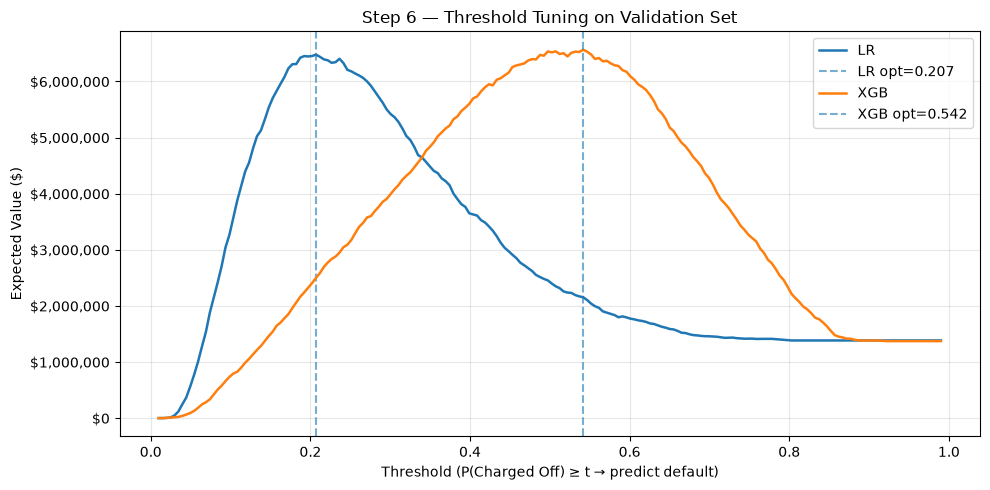

LR — Best threshold: 0.2070 | Val EV: $6,476,313.22 | EV/loan: $405.07
XGB — Best threshold: 0.5419 | Val EV: $6,563,869.94 | EV/loan: $410.55


In [7]:
N_THRESHOLDS = 200
thresholds = np.linspace(0.01, 0.99, N_THRESHOLDS)
threshold_results = {}

for name in ['lr', 'xgb']:
    proba = predict_proba_positive(models[name], preprocessed[name]['val'])
    ev_list = []
    for t in thresholds:
        y_pred = (proba >= t).astype(int)
        ev = compute_expected_value(y_val.values, y_pred, business_params)
        ev_list.append(ev)
    
    ev_arr = np.array(ev_list)
    best_idx = np.argmax(ev_arr)
    threshold_results[name] = {
        'best_threshold': thresholds[best_idx],
        'best_ev': ev_arr[best_idx],
        'thresholds': thresholds,
        'ev_curve': ev_arr,
        'val_proba': proba,
    }

# ── Plot ──
fig, ax = plt.subplots(figsize=(10, 5))
for name, r in threshold_results.items():
    ax.plot(r['thresholds'], r['ev_curve'], label=name.upper(), linewidth=1.8)
    ax.axvline(r['best_threshold'], ls='--', alpha=0.6,
               label=f"{name.upper()} opt={r['best_threshold']:.3f}")
ax.set_xlabel('Threshold (P(Charged Off) ≥ t → predict default)')
ax.set_ylabel('Expected Value ($)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Step 6 — Threshold Tuning on Validation Set')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for name, r in threshold_results.items():
    print(f"{name.upper()} — Best threshold: {r['best_threshold']:.4f} | "
          f"Val EV: ${r['best_ev']:,.2f} | EV/loan: ${r['best_ev']/len(y_val):.2f}")

---
## Step 7 — Baseline Comparison
เปรียบเทียบ model กับ 3 strategies: Approve All / Reject All / FICO < 670 Rule

In [8]:
rows = []

# Approve all
y_all0 = np.zeros(len(y_val), dtype=int)
ev0 = compute_expected_value(y_val.values, y_all0, business_params)
rows.append({'Strategy': 'Approve All', 'Threshold': '—', 'Val EV ($)': ev0, 'EV/Loan ($)': ev0/len(y_val)})

# Reject all
y_all1 = np.ones(len(y_val), dtype=int)
ev1 = compute_expected_value(y_val.values, y_all1, business_params)
rows.append({'Strategy': 'Reject All', 'Threshold': '—', 'Val EV ($)': ev1, 'EV/Loan ($)': ev1/len(y_val)})

# FICO rule
fico_avg = (X_val['fico_range_low'] + X_val['fico_range_high']) / 2
y_fico = (fico_avg < 670).astype(int)
ev_fico = compute_expected_value(y_val.values, y_fico.values, business_params)
rows.append({'Strategy': 'FICO < 670 Rule', 'Threshold': '670', 'Val EV ($)': ev_fico, 'EV/Loan ($)': ev_fico/len(y_val)})

# Model results
for name, r in threshold_results.items():
    rows.append({
        'Strategy': f'{name.upper()} Model',
        'Threshold': f"{r['best_threshold']:.4f}",
        'Val EV ($)': r['best_ev'],
        'EV/Loan ($)': r['best_ev'] / len(y_val),
    })

baseline_df = pd.DataFrame(rows).sort_values('Val EV ($)', ascending=False).reset_index(drop=True)
baseline_df.style.format({'Val EV ($)': '${:,.0f}', 'EV/Loan ($)': '${:.2f}'})

,Strategy,Threshold,Val EV ($),EV/Loan ($)
0,XGB Model,0.5419,"$6,563,870",$410.55
1,LR Model,0.2070,"$6,476,313",$405.07
2,FICO < 670 Rule,670,"$2,697,775",$168.74
3,Approve All,—,"$1,371,823",$85.80
4,Reject All,—,$0,$0.00


---
## Step 8 — ROC + Precision-Recall Curve

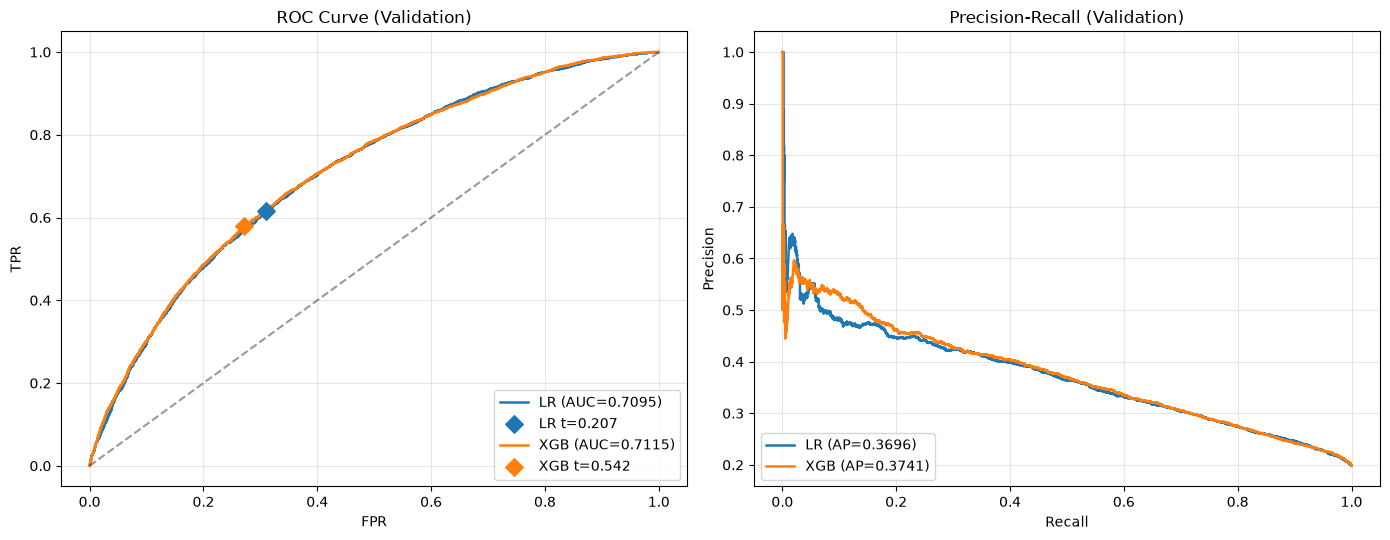

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for name in ['lr', 'xgb']:
    proba = threshold_results[name]['val_proba']
    t_opt = threshold_results[name]['best_threshold']
    
    # ROC
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc = roc_auc_score(y_val, proba)
    axes[0].plot(fpr, tpr, label=f'{name.upper()} (AUC={auc:.4f})', lw=1.8)
    
    # Mark optimal threshold
    y_pred_opt = (proba >= t_opt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_opt).ravel()
    axes[0].scatter(fp/(fp+tn), tp/(tp+fn), s=80, zorder=5, marker='D',
                    label=f'{name.upper()} t={t_opt:.3f}')
    
    # PR
    prec, rec, _ = precision_recall_curve(y_val, proba)
    ap = average_precision_score(y_val, proba)
    axes[1].plot(rec, prec, label=f'{name.upper()} (AP={ap:.4f})', lw=1.8)

axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC Curve (Validation)')
axes[0].legend(loc='lower right'); axes[0].grid(True, alpha=0.3)

axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall (Validation)')
axes[1].legend(loc='lower left'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Step 8a — Probability Distribution + Threshold Annotation
กราฟนี้อธิบายว่าทำไม LR t=0.17 vs XGB t=0.48 ถึงต่างกันมาก  
ทั้งที่ AUC แทบเท่ากัน — เพราะ **distribution ของ predicted probability ต่างกัน**

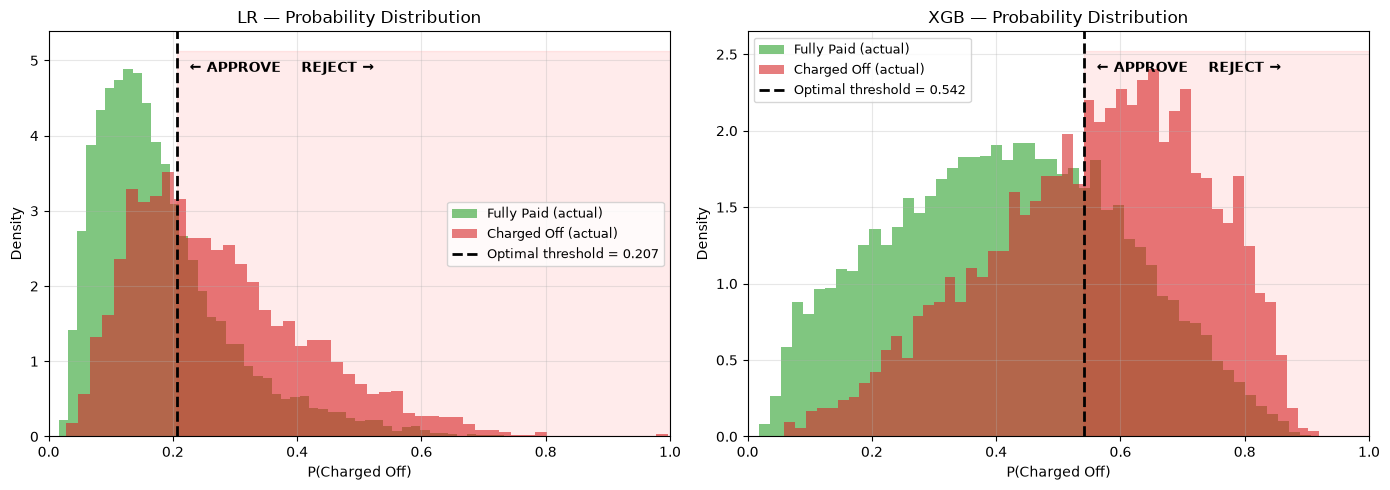

📊 Probability Distribution Summary:
  LR: min=0.0160 | median=0.1704 | max=0.9964 | threshold=0.207 | reject rate=37.1%
  XGB: min=0.0183 | median=0.4480 | max=0.9194 | threshold=0.542 | reject rate=33.3%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, name in enumerate(['lr', 'xgb']):
    ax = axes[idx]
    proba = threshold_results[name]['val_proba']
    t_opt = threshold_results[name]['best_threshold']
    
    # แยก histogram ตาม actual class
    mask_pos = y_val == 1  # Charged Off
    mask_neg = y_val == 0  # Fully Paid
    
    ax.hist(proba[mask_neg], bins=50, alpha=0.6, label='Fully Paid (actual)',
            color='#2ca02c', density=True)
    ax.hist(proba[mask_pos], bins=50, alpha=0.6, label='Charged Off (actual)',
            color='#d62728', density=True)
    
    # วาดเส้น threshold
    ax.axvline(t_opt, color='black', ls='--', lw=2,
               label=f'Optimal threshold = {t_opt:.3f}')
    ax.fill_betweenx([0, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 10],
                      t_opt, 1.0, alpha=0.08, color='red')
    ax.text(t_opt + 0.02, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] > 0 else 5,
            '← APPROVE    REJECT →', fontsize=10, fontweight='bold')
    
    ax.set_xlabel('P(Charged Off)')
    ax.set_ylabel('Density')
    ax.set_title(f'{name.upper()} — Probability Distribution')
    ax.legend(fontsize=9)
    ax.set_xlim(0, 1)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Stats summary
print('📊 Probability Distribution Summary:')
for name in ['lr', 'xgb']:
    proba = threshold_results[name]['val_proba']
    t = threshold_results[name]['best_threshold']
    pct_reject = (proba >= t).mean() * 100
    print(f'  {name.upper()}: min={proba.min():.4f} | median={np.median(proba):.4f} | '
          f'max={proba.max():.4f} | threshold={t:.3f} | reject rate={pct_reject:.1f}%')

---
## Step 9 — Calibration Check (Reliability Diagram)

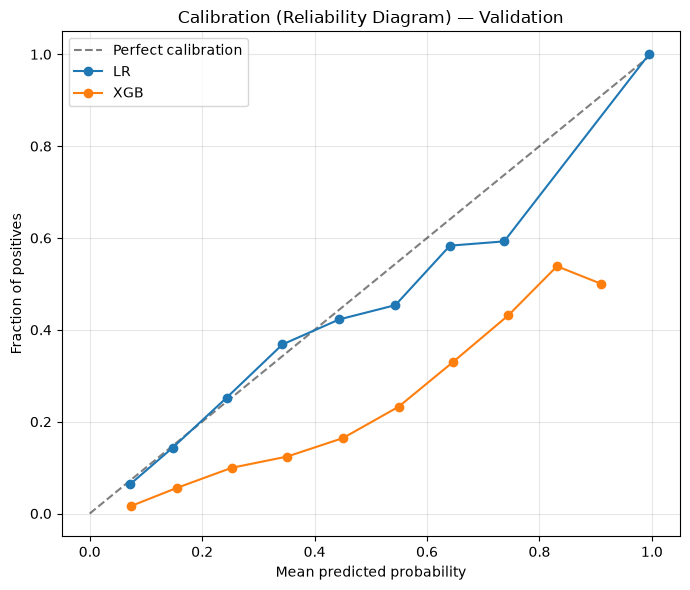

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0,1],[0,1],'k--',alpha=0.5,label='Perfect calibration')

for name in ['lr', 'xgb']:
    proba = threshold_results[name]['val_proba']
    frac_pos, mean_pred = calibration_curve(y_val, proba, n_bins=10, strategy='uniform')
    ax.plot(mean_pred, frac_pos, 'o-', label=name.upper(), lw=1.5)

ax.set(xlabel='Mean predicted probability', ylabel='Fraction of positives',
       title='Calibration (Reliability Diagram) — Validation')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 10 — Feature Importance (LR coef + XGB gain)

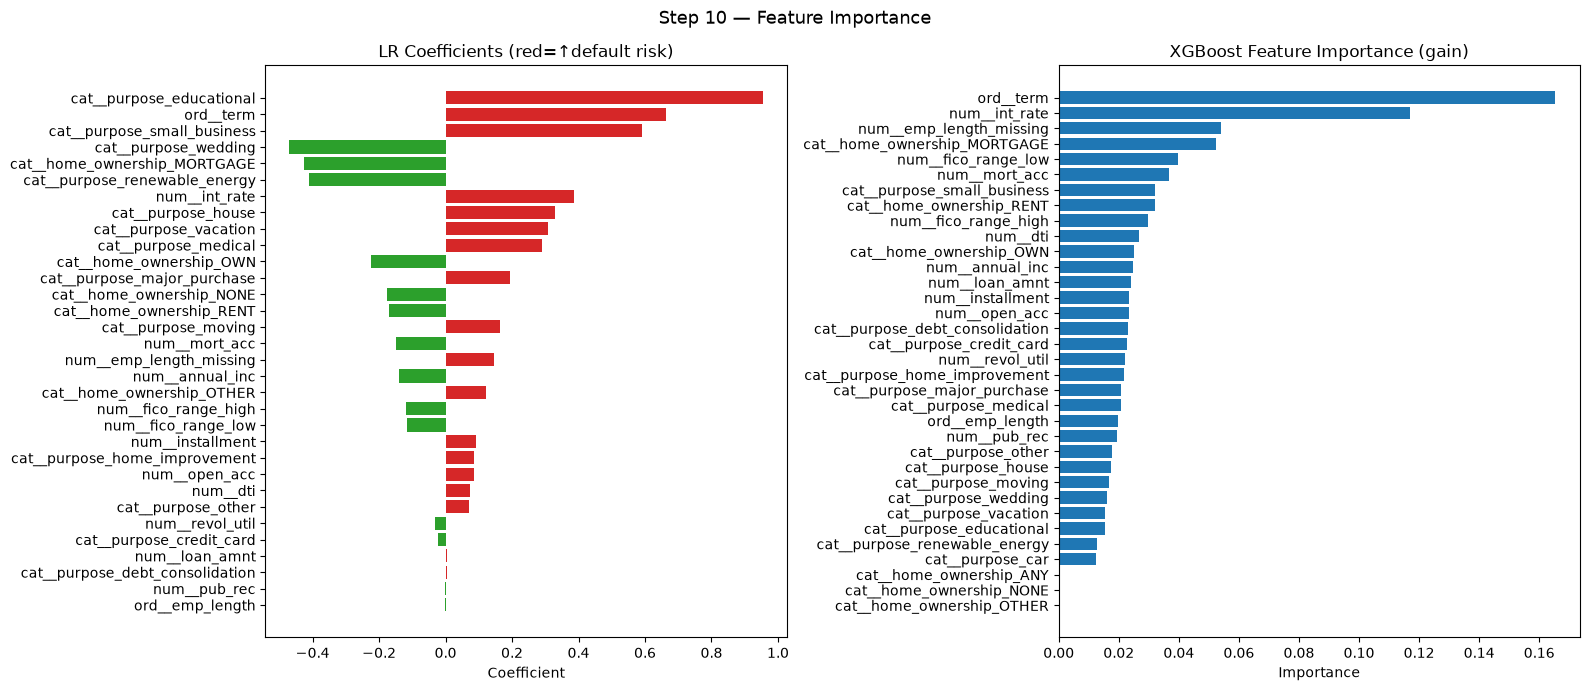

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# LR Coefficients
lr_names = preprocessed['lr']['feature_names']
lr_coefs = models['lr'].coef_[0]
lr_df = pd.DataFrame({'feature': lr_names, 'coef': lr_coefs})
lr_df = lr_df.reindex(lr_df['coef'].abs().sort_values(ascending=True).index)
colors = ['#d62728' if c > 0 else '#2ca02c' for c in lr_df['coef']]
axes[0].barh(lr_df['feature'], lr_df['coef'], color=colors)
axes[0].set_title('LR Coefficients (red=↑default risk)')
axes[0].set_xlabel('Coefficient')

# XGB Gain
xgb_names = preprocessed['xgb']['feature_names']
xgb_imp = models['xgb'].feature_importances_
xgb_df = pd.DataFrame({'feature': xgb_names, 'gain': xgb_imp})
xgb_df = xgb_df.sort_values('gain', ascending=True)
axes[1].barh(xgb_df['feature'], xgb_df['gain'], color='#1f77b4')
axes[1].set_title('XGBoost Feature Importance (gain)')
axes[1].set_xlabel('Importance')

fig.suptitle('Step 10 — Feature Importance', fontsize=13)
plt.tight_layout()
plt.show()

---
## Step 11 — SHAP Individual Explanation
SHAP summary plot + waterfall สำหรับ loan ตัวอย่าง 3 ราย

20:57:06 | INFO     | Computing SHAP values (TreeExplainer)...


── SHAP Summary Plot ──


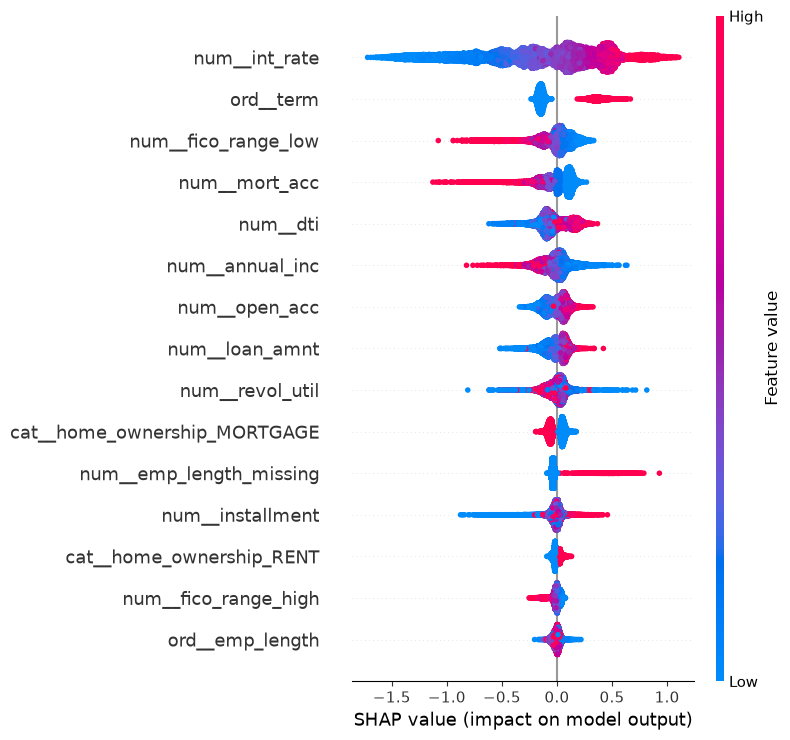

In [13]:
log.info('Computing SHAP values (TreeExplainer)...')
explainer = shap.TreeExplainer(models['xgb'])
X_val_xgb = preprocessed['xgb']['val']
feat_names = list(preprocessed['xgb']['feature_names'])
shap_values = explainer.shap_values(X_val_xgb)

# Summary plot
print('── SHAP Summary Plot ──')
shap.summary_plot(shap_values, X_val_xgb, feature_names=feat_names, show=True, max_display=15)


── Loan #0 Waterfall ──


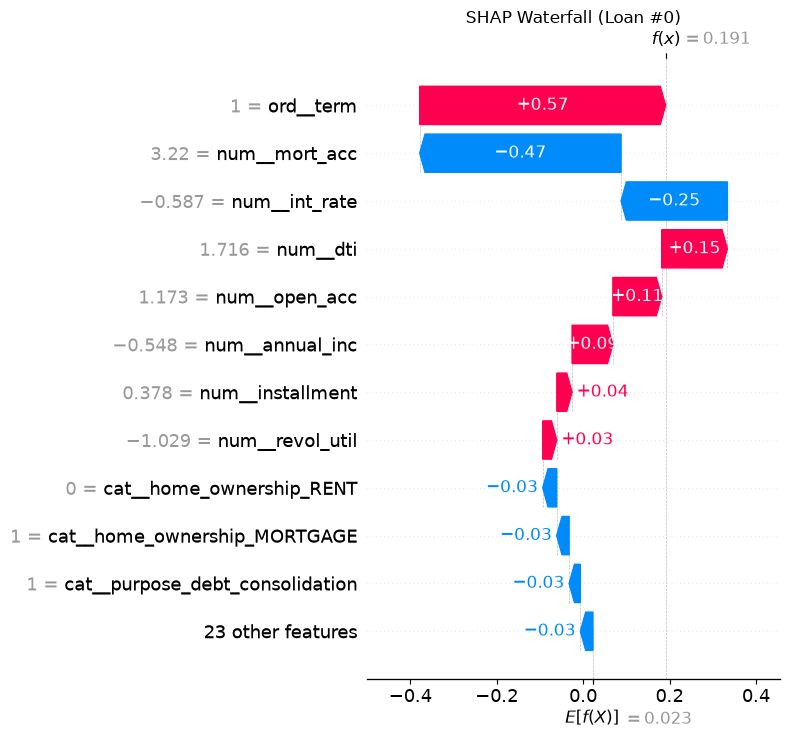


── Loan #1 Waterfall ──


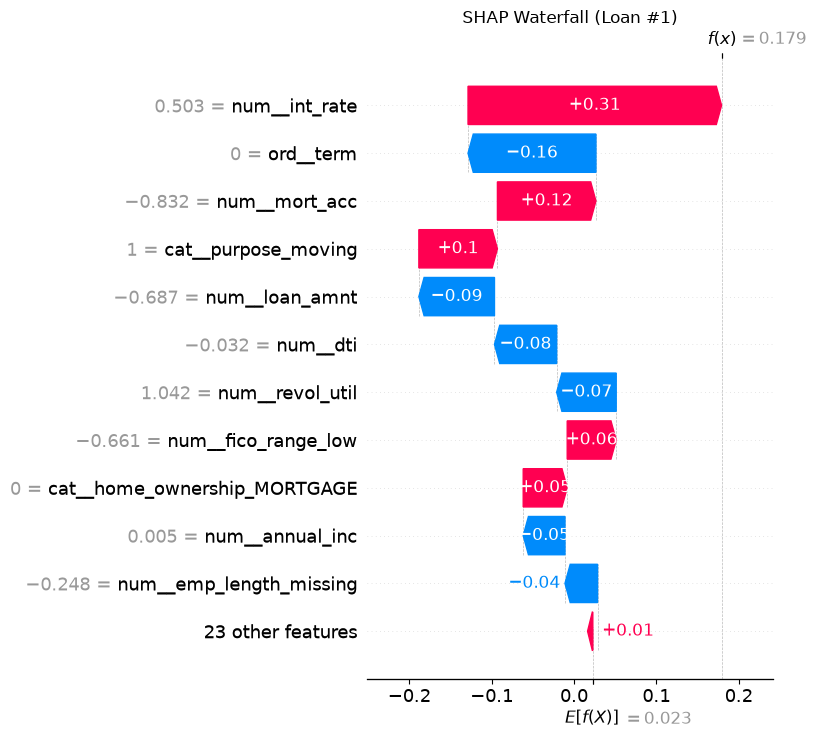


── Loan #2 Waterfall ──


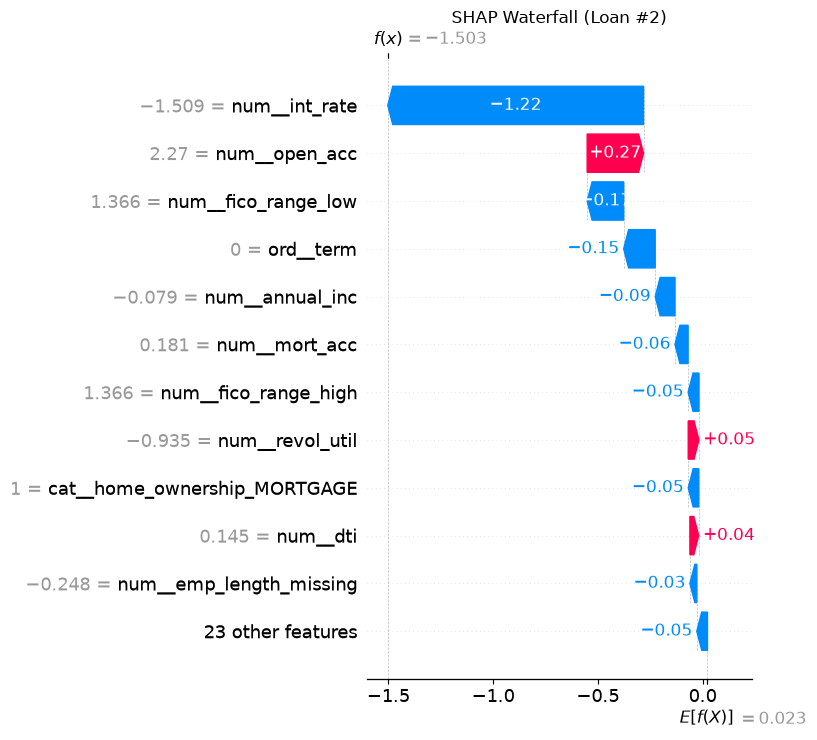

In [14]:
import numpy as np

# ── Waterfall for individual loans ──
n_explain = 3
base_val = explainer.expected_value

# วิธีเช็คที่ปลอดภัยกว่า: เช็คว่าเป็น List หรือ Numpy Array หรือไม่
if isinstance(base_val, (list, np.ndarray)):
    base_val = base_val[POSITIVE_CLASS]

# สร้าง SHAP Explanation Object
explanation = shap.Explanation(
    values=shap_values[:n_explain],
    base_values=base_val,
    data=X_val_xgb[:n_explain],
    feature_names=feat_names,  # ให้แน่ใจว่าตัวแปรนี้ดึงมาจาก preprocessed["xgb"]["feature_names"] นะครับ
)

for i in range(n_explain):
    print(f'\n── Loan #{i} Waterfall ──')
    fig = plt.figure(figsize=(10, 6))
    shap.waterfall_plot(explanation[i], show=False, max_display=12)
    plt.title(f"SHAP Waterfall (Loan #{i})")
    plt.tight_layout()
    plt.show()

---
## Step 12 — Sensitivity Analysis (Business Params)
เปลี่ยนค่า business param ±50% ดูว่า EV เปลี่ยนแค่ไหน

Base Sensitivity on: XGB (Base threshold=0.5419)
Base Confusion: TN=9333 FP=3487 FN=1332 TP=1836



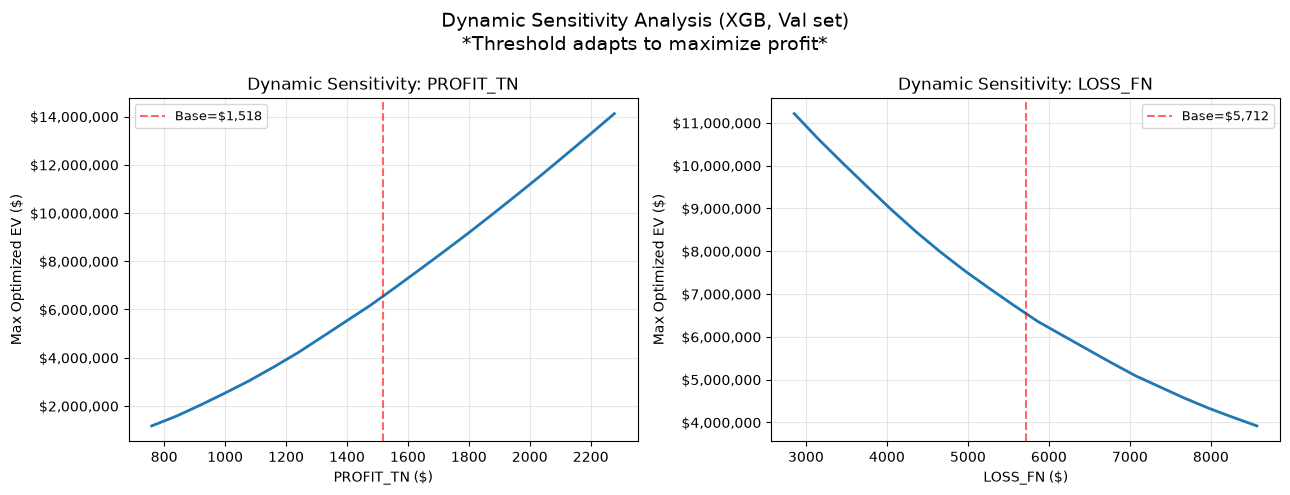

In [15]:
# Use model with higher Val EV
best_model_name = max(threshold_results, key=lambda k: threshold_results[k]['best_ev'])
proba_best = threshold_results[best_model_name]['val_proba']
t_best = threshold_results[best_model_name]['best_threshold']
y_pred_best = (proba_best >= t_best).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val.values, y_pred_best).ravel()

print(f'Base Sensitivity on: {best_model_name.upper()} (Base threshold={t_best:.4f})')
print(f'Base Confusion: TN={tn} FP={fp} FN={fn} TP={tp}\n')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
vary_pct = 0.5
# สร้างลิสต์ของจุดตัดเพื่อใช้จำลองหาจุดที่ดีที่สุดใหม่
threshold_candidates = np.linspace(0.01, 0.99, 100) 

for ax, param in zip(axes.ravel(), ['PROFIT_TN', 'LOSS_FN']):
    base = business_params[param]
    vals = np.linspace(base*(1-vary_pct), base*(1+vary_pct), 20)
    evs = []
    
    for v in vals:
        bp = business_params.copy()
        bp[param] = v
        
        # 🌟 จุดที่อัปเกรด: หา Threshold ใหม่ที่ดีที่สุดสำหรับสถานการณ์นี้
        best_ev_dynamic = -np.inf
        
        for t in threshold_candidates:
            y_pred_tmp = (proba_best >= t).astype(int)
            tn_tmp, fp_tmp, fn_tmp, tp_tmp = confusion_matrix(y_val.values, y_pred_tmp).ravel()
            current_ev = (tn_tmp*bp['PROFIT_TN'] - fn_tmp*bp['LOSS_FN'] - fp_tmp*bp['COST_FP'] + tp_tmp*bp['REWARD_TP'])
            
            if current_ev > best_ev_dynamic:
                best_ev_dynamic = current_ev
                
        # เก็บค่ากำไรที่ "ดีที่สุด" (หลังจากโมเดลปรับตัวแล้ว)
        evs.append(best_ev_dynamic)
        
    ax.plot(vals, evs, lw=2.0, color='#1f77b4')
    ax.axvline(base, color='red', ls='--', alpha=0.6, label=f'Base=${base:,.0f}')
    ax.set_xlabel(f'{param} ($)'); ax.set_ylabel('Max Optimized EV ($)')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.set_title(f'Dynamic Sensitivity: {param}')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

fig.suptitle(f'Dynamic Sensitivity Analysis ({best_model_name.upper()}, Val set)\n*Threshold adapts to maximize profit*', fontsize=14)
plt.tight_layout()
plt.show()

---
## Step 13 — Cross-Validation EV (5-fold)
5-fold stratified CV บน Training set → วัด mean ± std ของ EV/loan  
⏱️ cell นี้ใช้เวลาสักครู่ (train 10 models: 5 folds × 2 models)

In [16]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
cv_records = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    Xf_tr, yf_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    Xf_va, yf_va = X_train.iloc[val_idx],   y_train.iloc[val_idx]
    
    for name, drop_first in [('lr', True), ('xgb', False)]:
        pre = _build_preprocessor(drop_first=drop_first)
        Xf_tr_t = pre.fit_transform(Xf_tr)
        Xf_va_t = pre.transform(Xf_va)
        
        if name == 'lr':
            mdl = LogisticRegression(solver='saga', penalty='l2', C=1.0,
                                     max_iter=2000, random_state=RANDOM_STATE, n_jobs=-1)
            mdl.fit(Xf_tr_t, yf_tr)
        else:
            pw = (yf_tr==0).sum() / (yf_tr==1).sum()
            mdl = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                     subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw,
                                     eval_metric='auc', use_label_encoder=False,
                                     random_state=RANDOM_STATE, n_jobs=-1)
            mdl.fit(Xf_tr_t, yf_tr, verbose=False)
        
        proba = mdl.predict_proba(Xf_va_t)[:, POSITIVE_CLASS]
        
        # Tune threshold per fold
        best_ev, best_t = -np.inf, 0.5
        for t in np.linspace(0.05, 0.95, 100):
            yp = (proba >= t).astype(int)
            ev = compute_expected_value(yf_va.values, yp, business_params)
            if ev > best_ev:
                best_ev, best_t = ev, t
        
        cv_records.append({
            'fold': fold, 'model': name.upper(), 'threshold': best_t,
            'ev_total': best_ev, 'ev_per_loan': best_ev/len(yf_va),
            'auc': roc_auc_score(yf_va, proba),
        })
    log.info('Fold %d done', fold)

cv_df = pd.DataFrame(cv_records)
summary = cv_df.groupby('model').agg(
    ev_per_loan_mean=('ev_per_loan','mean'),
    ev_per_loan_std=('ev_per_loan','std'),
    auc_mean=('auc','mean'),
    auc_std=('auc','std'),
).reset_index()

print('── 5-Fold CV Summary ──')
summary.style.format({
    'ev_per_loan_mean': '${:.2f}', 'ev_per_loan_std': '${:.2f}',
    'auc_mean': '{:.4f}', 'auc_std': '{:.4f}'
})

20:57:53 | INFO     | Fold 1 done


20:58:21 | INFO     | Fold 2 done


20:58:44 | INFO     | Fold 3 done


20:59:11 | INFO     | Fold 4 done


20:59:38 | INFO     | Fold 5 done


── 5-Fold CV Summary ──


,model,ev_per_loan_mean,ev_per_loan_std,auc_mean,auc_std
0,LR,$398.48,$20.40,0.7066,0.0081
1,XGB,$394.19,$14.92,0.7068,0.0068


---
## Step 14 — Final Evaluation (Test set — ครั้งเดียว) 🎯

> ⚠️ **นี่คือ cell สุดท้าย** — ใช้ threshold ที่ tune จาก Val ยิงบน Test set **ครั้งเดียวเท่านั้น**

In [17]:
print('=' * 60)
print('   FINAL EVALUATION ON TEST SET (one-time only)')
print('=' * 60)

final_rows = []
for name in ['lr', 'xgb']:
    t_opt = threshold_results[name]['best_threshold']
    proba = predict_proba_positive(models[name], preprocessed[name]['test'])
    y_pred = (proba >= t_opt).astype(int)
    
    ev = compute_expected_value(y_test.values, y_pred, business_params)
    auc = roc_auc_score(y_test, proba)
    tn, fp, fn, tp = confusion_matrix(y_test.values, y_pred).ravel()
    
    print(f'\n── {name.upper()} (threshold={t_opt:.4f}) ──')
    print(f'  Test EV:      ${ev:>12,.2f}')
    print(f'  Test EV/loan: ${ev/len(y_test):>12.2f}')
    print(f'  Test AUC:     {auc:.4f}')
    print(f'  TN={tn}  FP={fp}  FN={fn}  TP={tp}')
    print(classification_report(y_test, y_pred, target_names=['Fully Paid', 'Charged Off']))
    
    final_rows.append({
        'Model': name.upper(), 'Threshold': t_opt,
        'Test EV ($)': ev, 'EV/Loan ($)': ev/len(y_test),
        'AUC': auc, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    })

print('\n── Final Comparison ──')
final_df = pd.DataFrame(final_rows)
final_df.style.format({
    'Threshold': '{:.4f}', 'Test EV ($)': '${:,.0f}',
    'EV/Loan ($)': '${:.2f}', 'AUC': '{:.4f}'
})

   FINAL EVALUATION ON TEST SET (one-time only)

── LR (threshold=0.2070) ──
  Test EV:      $6,495,551.26
  Test EV/loan: $      406.28
  Test AUC:     0.7114
  TN=8878  FP=3942  FN=1223  TP=1945
              precision    recall  f1-score   support

  Fully Paid       0.88      0.69      0.77     12820
 Charged Off       0.33      0.61      0.43      3168

    accuracy                           0.68     15988
   macro avg       0.60      0.65      0.60     15988
weighted avg       0.77      0.68      0.71     15988


── XGB (threshold=0.5419) ──
  Test EV:      $6,352,167.74
  Test EV/loan: $      397.31
  Test AUC:     0.7079
  TN=9329  FP=3491  FN=1368  TP=1800
              precision    recall  f1-score   support

  Fully Paid       0.87      0.73      0.79     12820
 Charged Off       0.34      0.57      0.43      3168

    accuracy                           0.70     15988
   macro avg       0.61      0.65      0.61     15988
weighted avg       0.77      0.70      0.72     15988


,Model,Threshold,Test EV ($),EV/Loan ($),AUC,TN,FP,FN,TP
0,LR,0.2070,"$6,495,551",$406.28,0.7114,8878,3942,1223,1945
1,XGB,0.5419,"$6,352,168",$397.31,0.7079,9329,3491,1368,1800


In [18]:
# ========================================
# Step 15 — Loan Pricing Engine
# ========================================

def calculate_min_rate(p_default, loss_fn, loan_amnt):
    """แปลง P(default) เป็นอัตราดอกเบี้ยขั้นต่ำที่คุ้มทุน"""
    if p_default >= 0.99:
        return None
    min_rate = (p_default * loss_fn) / ((1 - p_default) * loan_amnt)
    return round(min_rate * 100, 2)

def assign_risk_tier(p_default):
    if p_default < 0.10:   return "A — LOW RISK"
    elif p_default < 0.20: return "B — MEDIUM RISK"
    elif p_default < 0.35: return "C — HIGH RISK"
    else:                  return "D — VERY HIGH RISK"

# ── คำนวณ pricing ให้ทุกคนใน Test set ──
proba_test = predict_proba_positive(models['xgb'], preprocessed['xgb']['test'])

pricing_df = pd.DataFrame({
    'actual': y_test.map({0: 'Fully Paid', 1: 'Charged Off'}),
    'p_default': proba_test,
    'loan_amnt': X_test['loan_amnt'].values,
    'original_rate': X_test['int_rate'].values,
})

pricing_df['risk_tier'] = pricing_df['p_default'].apply(assign_risk_tier)
pricing_df['min_rate'] = pricing_df.apply(
    lambda r: calculate_min_rate(r['p_default'], business_params['LOSS_FN'], r['loan_amnt']),
    axis=1
)
pricing_df['recommended_rate'] = (pricing_df['min_rate'] * 1.3).round(2)  # +30% margin
pricing_df['decision'] = pricing_df.apply(
    lambda r: 'REJECT' if r['min_rate'] and r['min_rate'] > 36 
              else 'APPROVE', axis=1
)

# ── แสดงตัวอย่าง 10 ราย ──
print('📋 ตัวอย่าง Pricing Engine Output (10 ราย):')
print('=' * 95)
sample = pricing_df.sample(10, random_state=42).sort_values('p_default')
for _, row in sample.iterrows():
    print(f"  P(default)={row['p_default']:.3f} | {row['risk_tier']:20s} | "
          f"Min rate={row['min_rate']:>5.1f}% | Recommended={row['recommended_rate']:>5.1f}% | "
          f"Original={row['original_rate']:>5.1f}% | {row['decision']:7s} | Actual={row['actual']}")

# ── สรุปตาม Risk Tier ──
print(f'\n📊 สรุปตาม Risk Tier:')
summary = pricing_df.groupby('risk_tier').agg(
    count=('p_default', 'size'),
    avg_p_default=('p_default', 'mean'),
    avg_min_rate=('min_rate', 'mean'),
    avg_recommended=('recommended_rate', 'mean'),
    actual_default_rate=('actual', lambda x: (x == 'Charged Off').mean()),
).round(4)
summary.style.format({
    'avg_p_default': '{:.2%}', 'avg_min_rate': '{:.1f}%',
    'avg_recommended': '{:.1f}%', 'actual_default_rate': '{:.2%}'
})

📋 ตัวอย่าง Pricing Engine Output (10 ราย):
  P(default)=0.144 | B — MEDIUM RISK      | Min rate=  6.8% | Recommended=  8.9% | Original=  7.0% | APPROVE | Actual=Fully Paid
  P(default)=0.195 | B — MEDIUM RISK      | Min rate=  5.5% | Recommended=  7.2% | Original=  7.5% | APPROVE | Actual=Fully Paid
  P(default)=0.238 | C — HIGH RISK        | Min rate=  7.2% | Recommended=  9.3% | Original=  6.1% | APPROVE | Actual=Fully Paid
  P(default)=0.254 | C — HIGH RISK        | Min rate= 38.9% | Recommended= 50.5% | Original= 10.4% | REJECT  | Actual=Fully Paid
  P(default)=0.361 | D — VERY HIGH RISK   | Min rate= 20.2% | Recommended= 26.3% | Original=  8.2% | APPROVE | Actual=Fully Paid
  P(default)=0.402 | D — VERY HIGH RISK   | Min rate= 19.2% | Recommended= 24.9% | Original=  9.8% | APPROVE | Actual=Fully Paid
  P(default)=0.527 | D — VERY HIGH RISK   | Min rate= 21.2% | Recommended= 27.6% | Original= 17.3% | APPROVE | Actual=Fully Paid
  P(default)=0.548 | D — VERY HIGH RISK   | Min rate= 

,count,avg_p_default,avg_min_rate,avg_recommended,actual_default_rate
risk_tier,,,,,
A — LOW RISK,590,7.19%,5.4%,7.0%,2.03%
B — MEDIUM RISK,1448,15.27%,12.5%,16.3%,5.94%
C — HIGH RISK,3311,28.06%,28.1%,36.6%,10.03%
D — VERY HIGH RISK,10639,55.14%,79.5%,103.4%,25.74%


📊 Stress Test Results (XGB, threshold=0.5419)
   Base default rate: 19.8%

 Stress (%) Default Rate        EV ($)  EV/Loan ($)   Status
          0        19.8%  6.563870e+06   410.549784 ✅ Profit
          5        23.8%  3.396959e+06   212.469296 ✅ Profit
         10        27.8% -1.170104e+05    -7.318642   ❌ Loss
         15        31.8% -3.377916e+06  -211.278230   ❌ Loss
         20        35.9% -6.942499e+06  -434.231838   ❌ Loss
         25        39.9% -1.039863e+07  -650.401868   ❌ Loss
         30        43.9% -1.374630e+07  -859.788319   ❌ Loss
         40        51.9% -2.038379e+07 -1274.943313   ❌ Loss
         50        59.9% -2.697791e+07 -1687.384876   ❌ Loss

⚠️  Breakeven point: default rate เพิ่มขึ้น ~10% จึงเริ่มขาดทุน


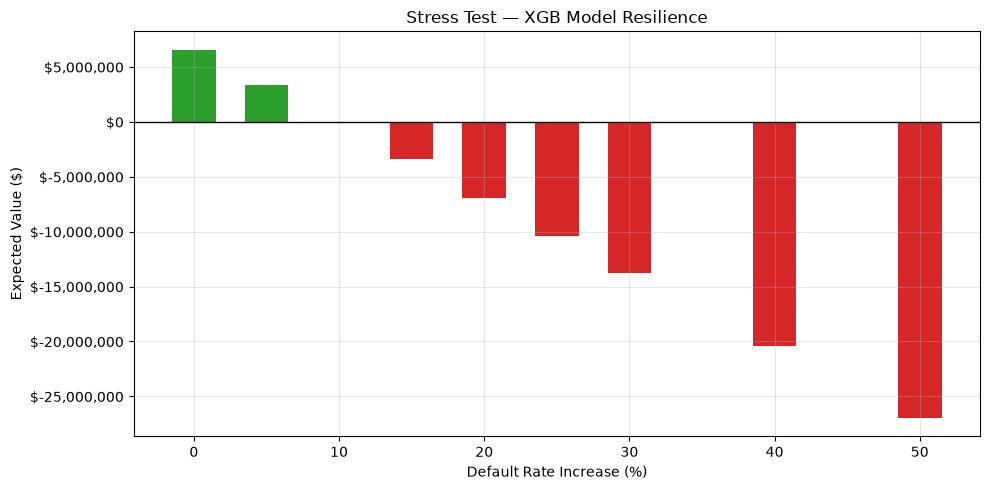

In [19]:
# ========================================
# Step 15 — Stress Test Simulation
# ========================================
# สมมติ: เศรษฐกิจแย่ลง → default rate เพิ่มขึ้น x%
# คำถาม: โมเดลยังทำกำไรไหม? ที่จุดไหนเริ่มขาดทุน?

np.random.seed(42)

stress_levels = [0, 5, 10, 15, 20, 25, 30, 40, 50]  # % default เพิ่ม
best_name = max(threshold_results, key=lambda k: threshold_results[k]['best_ev'])
t_opt = threshold_results[best_name]['best_threshold']
proba = threshold_results[best_name]['val_proba']

results = []
for stress in stress_levels:
    # จำลอง: คนที่จริงๆ Fully Paid บางส่วนกลายเป็น default
    y_stressed = y_val.to_numpy(dtype=np.int64, copy=True)
    fully_paid_idx = np.where(y_stressed == 0)[0]
    n_flip = int(len(fully_paid_idx) * stress / 100)
    flip_idx = np.random.choice(fully_paid_idx, size=n_flip, replace=False)
    y_stressed[flip_idx] = 1
    
    actual_default_rate = y_stressed.mean()
    
    # ใช้ threshold เดิม ไม่ปรับ (เพราะ production จะไม่รู้ล่วงหน้า)
    y_pred = (proba >= t_opt).astype(int)
    ev = compute_expected_value(y_stressed, y_pred, business_params)
    
    results.append({
        'Stress (%)': stress,
        'Default Rate': f'{actual_default_rate:.1%}',
        'EV ($)': ev,
        'EV/Loan ($)': ev / len(y_val),
        'Status': '✅ Profit' if ev > 0 else '❌ Loss'
    })

stress_df = pd.DataFrame(results)
print(f'📊 Stress Test Results ({best_name.upper()}, threshold={t_opt:.4f})')
print(f'   Base default rate: {y_val.mean():.1%}\n')
print(stress_df.to_string(index=False))

# หาจุดที่เริ่มขาดทุน (breakeven)
evs = [r['EV ($)'] for r in results]
for i in range(len(evs)-1):
    if evs[i] > 0 and evs[i+1] <= 0:
        breakeven = stress_levels[i] + (stress_levels[i+1]-stress_levels[i]) * evs[i]/(evs[i]-evs[i+1])
        print(f'\n⚠️  Breakeven point: default rate เพิ่มขึ้น ~{breakeven:.0f}% จึงเริ่มขาดทุน')
        break
else:
    if evs[-1] > 0:
        print(f'\n✅ โมเดลยังทำกำไรแม้ default rate เพิ่มขึ้น {stress_levels[-1]}%')
    else:
        print(f'\n❌ โมเดลขาดทุนตั้งแต่ stress level ต่ำ')

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
evs_plot = [r['EV ($)'] for r in results]
colors = ['#2ca02c' if e > 0 else '#d62728' for e in evs_plot]
ax.bar(stress_levels, evs_plot, color=colors, width=3)
ax.axhline(y=0, color='black', linewidth=1)
ax.set_xlabel('Default Rate Increase (%)')
ax.set_ylabel('Expected Value ($)')
ax.set_title(f'Stress Test — {best_name.upper()} Model Resilience')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 16 — Export results for the dashboard
บันทึกตัวเลขจริงจาก notebook ลง `docs/data/` เพื่อให้ `src/create_dashboard.py` อ่านไปทำ dashboard และ Power BI

In [20]:
ROOT = Path('.') if Path('docs').exists() else Path('..')
OUT = ROOT / 'docs' / 'data'
OUT.mkdir(parents=True, exist_ok=True)

# 1) Business parameters
pd.DataFrame({
    'Parameter': ['Profit per repaid loan (TN)', 'Loss per defaulted loan (FN)',
                  'Rejecting a good loan (FP)', 'Rejecting a bad loan (TP)'],
    'Value_USD': [business_params[k] for k in ['PROFIT_TN', 'LOSS_FN', 'COST_FP', 'REWARD_TP']],
}).round(2).to_csv(OUT / 'business_parameters.csv', index=False)

# 2) Strategy comparison on the validation set
cmp_df = baseline_df[['Strategy', 'Threshold', 'EV/Loan ($)']].rename(columns={'EV/Loan ($)': 'EV_per_Loan'})
cmp_df['EV_per_Loan'] = cmp_df['EV_per_Loan'].astype(float).round(2)
cmp_df.to_csv(OUT / 'model_comparison.csv', index=False)

# 3) EV per loan at every threshold (validation set)
pd.DataFrame({
    'Threshold': threshold_results['xgb']['thresholds'],
    'EV_XGBoost': threshold_results['xgb']['ev_curve'] / len(y_val),
    'EV_LogisticRegression': threshold_results['lr']['ev_curve'] / len(y_val),
}).round(4).to_csv(OUT / 'ev_threshold_curve.csv', index=False)

# 4) SHAP importance = mean |SHAP| per feature (XGBoost, validation set)
clean = lambda n: n.split('__', 1)[-1]  # 'num__int_rate' -> 'int_rate'
shap_imp = (pd.DataFrame({'Feature': [clean(f) for f in feat_names], 'SHAP_Importance': np.abs(shap_values).mean(axis=0)})
            .sort_values('SHAP_Importance', ascending=False).head(10))
shap_imp['SHAP_Importance'] = shap_imp['SHAP_Importance'].round(4)
shap_imp.to_csv(OUT / 'feature_importance.csv', index=False)

# 5) Final test-set results
test_out = pd.DataFrame(final_rows)
test_out['Approval_Rate'] = (test_out['TN'] + test_out['FN']) / len(y_test)
test_out.round(4).to_csv(OUT / 'test_results_summary.csv', index=False)

print('Saved to', OUT.resolve())
print(shap_imp.to_string(index=False))
print(test_out[['Model', 'Threshold', 'EV/Loan ($)', 'AUC', 'Approval_Rate']].round(4).to_string(index=False))


Saved to /Users/thanakit/github-projects/credit-risk-analytics/docs/data
                Feature  SHAP_Importance
               int_rate           0.4534
                   term           0.2031
         fico_range_low           0.1252
               mort_acc           0.1141
                    dti           0.1140
             annual_inc           0.0964
               open_acc           0.0794
              loan_amnt           0.0779
             revol_util           0.0637
home_ownership_MORTGAGE           0.0613
Model  Threshold  EV/Loan ($)    AUC  Approval_Rate
   LR     0.2070     406.2767 0.7114         0.6318
  XGB     0.5419     397.3085 0.7079         0.6691
